# Pensión de los mayores frente al salario de quienes están a punto de jubilarse

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "tasa-sustitucion-pensiones"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Pensión de los mayores frente al salario de quienes están a punto de jubilarse"  # `titulo` en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de los ingresos del trabajo de las personas de 50 a 59 años"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** La pensión bruta mediana de las personas de 65 a 74 años en porcentaje de los ingresos brutos del trabajo medianos de las personas de 50 a 59 años. Es la *tasa de sustitución agregada* de las pensiones: compara lo que cobran quienes acaban de jubilarse con lo que ganan quienes están a punto de hacerlo.

**Cómo se lee.** Un valor de 80 significa que la pensión mediana de las personas de 65 a 74 años equivale al 80 % de los ingresos del trabajo medianos de las de 50 a 59. Cuanto más alto, menos cae la renta al jubilarse.

**Limitaciones.**
- Compara grupos distintos de personas en un mismo año, no la pensión de cada persona con su último salario.
- Mide la renta, no el nivel de vida: al jubilarse suelen bajar algunos gastos (los ligados al trabajo o la hipoteca si ya está pagada) y las pensiones no pagan cotizaciones sociales, así que una tasa por debajo de 100 no supone una caída igual del nivel de vida.
- Solo cuenta las pensiones (públicas y privadas) y no otras prestaciones sociales; usa importes brutos, antes de impuestos.
- Sale de la encuesta de condiciones de vida (EU-SILC): el año de la gráfica es el de la encuesta, y los ingresos son los del año anterior.
- **Solo Europa.** Eurostat no lo publica fuera de Europa. La tasa de sustitución de la OCDE (*Pensions at a Glance*) es otra cosa: una tasa *teórica*, calculada para un trabajador tipo que empieza a trabajar hoy y cotiza toda su vida con las reglas vigentes; no mide las pensiones que se cobran. Por eso la OCDE, EE. UU. y Canadá quedan vacíos; la sección 3 muestra la tasa teórica solo como contexto.

## 2. Descarga

- **España y UE-27:** Eurostat, tasa de sustitución agregada de las pensiones sin otras prestaciones sociales (`ilc_pnp3`), ambos sexos (`T`).
- **Contexto (no se publica):** OCDE, *Pensions at a Glance* (`OECD.ELS.SPD,DSD_PAG@DF_PAG,1.0`), tasa de sustitución bruta teórica de los planes obligatorios para un trabajador con el salario medio (`GPRR100`), España, EE. UU. y Canadá.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd
from lib.tipos import FuenteMeta

eu, fuentes_eu = eurostat.get("ilc_pnp3", {"freq": "A", "sex": "T", "unit": "PC"}, desde=DESDE)

# PAG: REF_AREA.FREQ.MEASURE.UNIT_MEASURE.SEX.AGE.OPTIONALITY (M = planes obligatorios)
DATAFLOW_PAG = "OECD.ELS.SPD,DSD_PAG@DF_PAG,1.0"
teorica, _ = oecd.get(
    DATAFLOW_PAG, "{AREA}.A.GPRR100.PT_EARN_G_PRE_RET_INC.M._Z.M",
    areas={"ESP": "espana", "USA": "eeuu", "CAN": "canada"}, desde=DESDE,
)

## 3. Transformación

Eurostat publica el indicador como cociente (p. ej. 0,6) aunque la unidad del dataset se llame «porcentaje»: se multiplica por 100 para expresarlo en porcentaje. La OCDE, EE. UU. y Canadá quedan en `null`.

In [ ]:
assert eu["valor"].max() < 2, "Eurostat ya publica el indicador en porcentaje: quitar la multiplicación por 100"
df = eu.assign(valor=eu["valor"] * 100)
HOY = fuentes_eu[0].fecha_consulta
fuentes = [
    FuenteMeta(f.serie, f.organismo, "ilc_pnp3 (sex=T; cociente × 100)", f.url, f.fecha_consulta) for f in fuentes_eu
]


def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, HOY) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


SIN = (eurostat.ORGANISMO, "ilc_pnp3: solo países europeos", eurostat.URL_DATABROWSER.format(dataset="ilc_pnp3"))
df, fuentes = anadir_sin_dato(df, fuentes, {"ocde": SIN, "eeuu": SIN, "canada": SIN})
display(df.pivot(index="periodo", columns="serie", values="valor").dropna(how="all").round(1))

print("Contexto, tasa de sustitución bruta teórica de la OCDE (no se publica):")
display(teorica.pivot(index="periodo", columns="serie", values="valor"))
ANIO_TEORICA = int(teorica["periodo"].max())

serie,canada,eeuu,espana,ocde,ue27
periodo,,,,,
2010,NaN,NaN,50.0,NaN,55.0
2011,NaN,NaN,54.0,NaN,56.0
2012,NaN,NaN,57.0,NaN,56.0
2013,NaN,NaN,62.0,NaN,58.0
2014,NaN,NaN,62.0,NaN,58.0
2015,NaN,NaN,65.0,NaN,59.0
2016,NaN,NaN,65.0,NaN,59.0
2017,NaN,NaN,70.0,NaN,60.0
2018,NaN,NaN,69.0,NaN,59.0


Contexto, tasa de sustitución bruta teórica de la OCDE (no se publica):


serie,canada,eeuu,espana
periodo,,,
2024,37.1,39.7,80.4


### Notas

In [ ]:
NOTAS = [
    "España y UE-27: Eurostat, tasa de sustitución agregada de las pensiones sin otras prestaciones sociales "
    "(ilc_pnp3): pensión individual bruta mediana de las personas de 65 a 74 años entre los ingresos brutos del "
    "trabajo medianos de las de 50 a 59, en porcentaje (Eurostat lo publica como cociente). Encuesta de condiciones de "
    "vida (EU-SILC): los ingresos son los del año anterior al de la encuesta. Media UE-27 de composición actual "
    "(EU27_2020).",
    "Compara grupos distintos de personas en el mismo año, no la pensión de cada persona con su último salario.",
    f"OCDE, EE. UU. y Canadá: sin dato. Eurostat no publica este indicador fuera de Europa, y la tasa de sustitución "
    f"de la OCDE (Pensions at a Glance, {ANIO_TEORICA}) es teórica: se calcula para un trabajador tipo que empieza a "
    f"trabajar hoy y no mide las pensiones que se cobran.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat, tasa de sustitución agregada de las pensiones sin otras prestaciones sociales (ilc_pnp3): pensión individual bruta mediana de las personas de 65 a 74 años entre los ingresos brutos del trabajo medianos de las de 50 a 59, en porcentaje (Eurostat lo publica como cociente). Encuesta de condiciones de vida (EU-SILC): los ingresos son los del año anterior al de la encuesta. Media UE-27 de composición actual (EU27_2020).
- Compara grupos distintos de personas en el mismo año, no la pensión de cada persona con su último salario.
- OCDE, EE. UU. y Canadá: sin dato. Eurostat no publica este indicador fuera de Europa, y la tasa de sustitución de la OCDE (Pensions at a Glance, 2024) es teórica: se calcula para un trabajador tipo que empieza a trabajar hoy y no mide las pensiones que se cobran.


## 4. Visualización

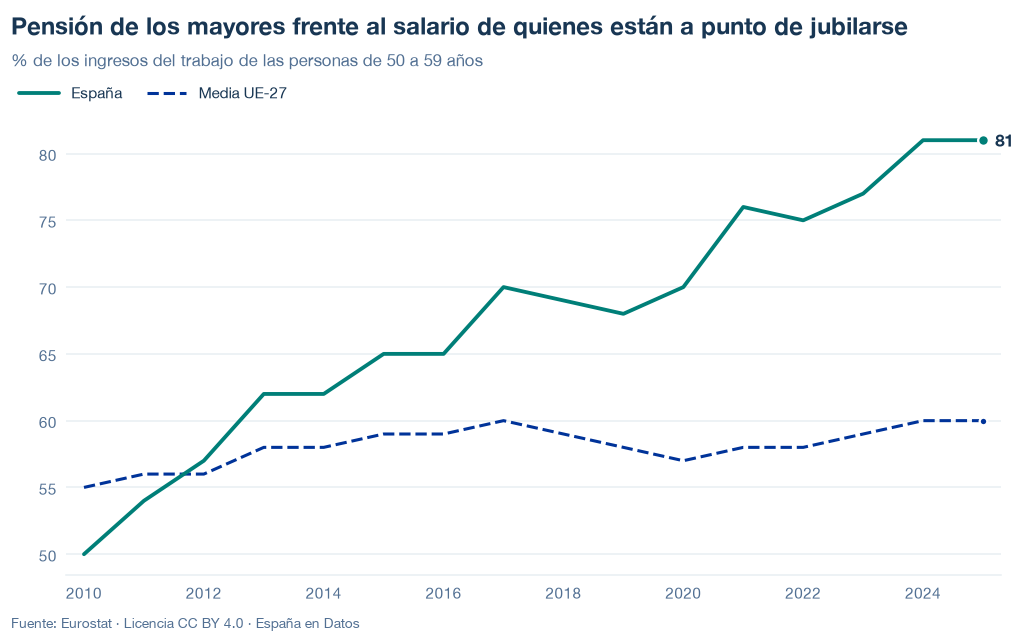

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/tasa-sustitucion-pensiones.json y data/tasa-sustitucion-pensiones.csv


## 6. Fuentes, notas y licencia

- Eurostat, `ilc_pnp3` (`T`): España y UE-27.
- OCDE, *Pensions at a Glance* (`OECD.ELS.SPD,DSD_PAG@DF_PAG,1.0`, `GPRR100`): solo como contexto en este notebook.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.